# 08 (PH) - Model tuning: a search over the hyperparameters, through the same script

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Keeps the families of 07 (LightGBM for the day, extra trees for the rest of the month, as they are); decided after 07 that the size of the extra trees model is no objection; ran the notebook on all rows and decided after the run to stop the search here (the winners sit on the edge of the space; 10 widens it) rather than probe further locally |
| Claude Code (AI assistant) | Drafted the search (the spaces, the random draw, the grid, the trial runner with its resume), the helpers in `modelling.py`, the tables, the chart, the checks and the dry run of 8 October (appendix). Logged in `genai-log.md` |

**Goal.** 07 trained each family once with sensible, untuned settings and read three leads from its outputs: the
day model is done after 100 trees, so the learning rate, the leaves and the objective are the axes to search, not
the number of trees; the squared error aims at the mean of a skewed count while the metric is the MAE; and the
extra trees have two real axes, the leaf size and the inputs per split. This notebook **searches those axes on all
rows**, every trial a run of `citibike/train/train.py` (07 §1), ranks the trials on the validation year, refits the
best configuration per horizon and puts it next to 07 on the same rows. 09 scores 05, 07, 08 and 10 on the test
period; 10 runs the same search on SageMaker, with these spaces.

**Products**

| Product | What it is |
| --- | --- |
| `models/citibike/08_search/<horizon>/<trial>/` | `metrics.json`, `predictions_valid.parquet` and `log.txt` of every trial; no model file (the winner is refitted) |
| the trial tables of parts 2 and 3 | every configuration with its validation MAE, WAPE, bias, fit time and, for LightGBM, its best number of trees |
| `models/citibike/08_<horizon>_<family>/` | the refitted winner per horizon: `model.joblib`, `metrics.json`, `predictions_valid.parquet` |
| the validation tables of 2.3 and 3.2 | the rules of 05, the ridge floor, the 07 model and the 08 model on the same rows |

**How it is built**
0. Setup.
1. What is searched, how, and why.
2. Horizon day: the trials, the curves, the refit and the validation table.
3. Horizon rest of month: the grid, the refit and the validation table.
4. Reading and what carries forward.
Appendix: the dry run of 8 October, the expected runtime, the failures to expect.

**Status: run on all rows on 8 October 2026 (team lead), in parts.** The dry run of the appendix ran every cell on a
station sample first; the reading in part 4 is written from the outputs of the full run and records the decision to
stop the search here.

## 0. Setup

Kernel "DataSpell", as 07; no database connection. The script is imported as in 07; `run_predictions()` and
`ridge_predictions()` (07's `predictions_of()` and `ridge_of()`) now live in `modelling.py`, because 09 needs them
too. The model inputs of 07 §2 must be on disk.

In [1]:
import json
import sys
import time
from contextlib import redirect_stdout

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

sys.path.insert(0, "..")         # citibike/ -> connection.py and modelling.py
sys.path.insert(0, "../train")   # citibike/train/ -> train.py
import train
from connection import fmt, notebook_style
from modelling import (load_features, scorable, score_table, rule_predictions, run_predictions, ridge_predictions,
                       MODEL_INPUTS_DIR, MODELS_DIR)

notebook_style()
print(f"python {sys.version.split()[0]}, scikit-learn {sklearn.__version__}, lightgbm {lightgbm.__version__}, pandas {pd.__version__}")

FAMILY = {"day": "lightgbm", "rest_of_month": "extra_trees"}      # as 07, unchanged
RUNS_07 = {horizon: MODELS_DIR / f"07_{horizon}_{family}" for horizon, family in FAMILY.items()}
RUNS_08 = {horizon: MODELS_DIR / f"08_{horizon}_{family}" for horizon, family in FAMILY.items()}
SEARCH_DIR = MODELS_DIR / "08_search"
SEED = 42
for horizon in FAMILY:
    assert (MODEL_INPUTS_DIR / horizon / "train.parquet").exists(), f"run 07 §2 first: no model inputs for {horizon}"
    assert (RUNS_07[horizon] / "predictions_valid.parquet").exists(), f"run 07 first: no run folder {RUNS_07[horizon].name}"

python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0, pandas 2.3.3


## 1. What is searched, how, and why

**Decision: a random search for LightGBM, a grid for the extra trees, both on all rows, both through `train.py`.**
The alternatives were a grid for both (with six axes a grid of 13 points can only hold two values of most
axes, a random draw of 13 points gives every continuous axis 13 distinct values), a search on the 10 % station sample of 06 (fast, but a leaf of 100
rows means something else on 250.000 rows than on 2,5 M: the leaf-size axes do not transfer), and a Bayesian
optimiser (a package more, and the sequential kind of search that SageMaker's automatic model tuning does for
us in 10). What makes the search on all rows affordable is 07's curve: a gradient boosting model with *k* trees is
the first *k* trees of a longer one, so one run of 500 trees with the validation MAE every 50 trees scores ten
numbers of trees at once. Each trial therefore has **two results**: its best number of trees and the MAE there.

**Horizon day: LightGBM, 13 trials.** Trial 0 is 07's configuration, so the search has to beat 07 under the same
protocol (500 trees, the best *k* read from the curve). Twelve trials are drawn at random, with a fixed seed, from:

| Axis | Values | Why this range |
| --- | --- | --- |
| `objective` | `regression` (squared error), `regression_l1` (absolute error), `poisson` | 07 §6: the squared error aims at the mean of a skewed count, the metric is the MAE (its median); Poisson is the natural loss for a count |
| `learning-rate` | 0,02 - 0,2, log-uniform | 07: at 0,05 the model is done after 100 trees; smaller steps may land lower, larger ones are cheaper |
| `num-leaves` | 15, 31, 63, 127, 255 | depth of each tree: how many interactions (weekday x weather x level) one tree can hold |
| `min-child-samples` | 20 ... 1.000 | the leaf floor: the regularisation that matters most for a noisy count at station level |
| `subsample`, `colsample-bytree` | 0,5 - 1,0 | the share of rows and inputs each tree sees: variance between trees against signal per tree |

**Horizon rest of month: extra trees, a grid of 6.** Extra trees have no learning rate and no objective to search;
their randomness is in the thresholds. Two axes matter: `min-samples-leaf` (50, 100, 200: the leaf floor, 07's is
100) and `max-features` (0,5 and 1,0: every split sees half of the inputs or all of them; 0,5 decorrelates the
trees and halves the fit time). The grid runs with **100 trees** (the ranking does not need 200: more trees only
lower the variance of the average) and the winner is refitted with 200, as 07. 07's point (100, 1,0) is in the
grid, so 07 is beaten or not under the same protocol.

**What every trial leaves behind.** `metrics.json`, `predictions_valid.parquet` and the script's output in `log.txt`,
in its own folder under `08_search/`; the model file is removed (the extra trees would be 250 MB each). A trial
whose `metrics.json` exists is read instead of rerun, so a kernel that dies after half an hour costs the trials
that were running, not the ones that were done. The ranking is on the **validation MAE** (05 - 07's metric);
WAPE and bias are shown next to it.

In [2]:
TREES_SEARCH = {"day": 500, "rest_of_month": 100}          # trees per trial; the curve picks k for LightGBM
TREES_FINAL = {"day": None, "rest_of_month": 200}          # None: the best k of the curve
N_RANDOM = 12                                              # random trials for LightGBM, next to trial 0 = 07
BASE_07 = {"day": {"objective": "regression", "learning-rate": 0.05, "num-leaves": 63, "min-child-samples": 100,
                   "subsample": 0.8, "colsample-bytree": 0.8},
           "rest_of_month": {"min-samples-leaf": 100, "max-features": 1.0}}
GRID_REST = [{"min-samples-leaf": leaf, "max-features": share} for leaf in (50, 100, 200) for share in (0.5, 1.0)]


def draw_lightgbm(rng: np.random.Generator) -> dict:
    """One random configuration of the day space of part 1."""
    return {"objective": str(rng.choice(["regression", "regression_l1", "poisson"])),
            "learning-rate": round(float(10 ** rng.uniform(np.log10(0.02), np.log10(0.2))), 3),
            "num-leaves": int(rng.choice([15, 31, 63, 127, 255])),
            "min-child-samples": int(rng.choice([20, 50, 100, 200, 500, 1000])),
            "subsample": round(float(rng.uniform(0.5, 1.0)), 2),
            "colsample-bytree": round(float(rng.uniform(0.5, 1.0)), 2)}


def trial(horizon: str, name: str, params: dict, folder=None, keep_model: bool = False) -> dict:
    """One run of train.py with params (names as on the command line) into folder (default 08_search/<horizon>/<name>).
    A trial that already has its metrics.json is read, not rerun. The script's output goes to log.txt; one line is printed."""
    folder = folder or SEARCH_DIR / horizon / name
    if (folder / "metrics.json").exists():
        result, status = json.loads((folder / "metrics.json").read_text(encoding="utf-8")), "read back"
    else:
        folder.mkdir(parents=True, exist_ok=True)
        argv = ["--family", FAMILY[horizon], "--horizon", horizon, "--model-dir", str(folder),
                "--train", str(MODEL_INPUTS_DIR / horizon / "train.parquet"), "--valid", str(MODEL_INPUTS_DIR / horizon / "valid.parquet")]
        argv += [token for key, value in params.items() for token in (f"--{key}", str(value))]
        t0 = time.time()
        with open(folder / "log.txt", "w", encoding="utf-8") as log, redirect_stdout(log):
            result = train.main(argv)
        status = f"{time.time() - t0:.0f} s"
        if not keep_model:
            (folder / "model.joblib").unlink()
    curve = {int(k): v for k, v in result.get("curve", {}).items()}
    best_k = min(curve, key=curve.get) if curve else result["hyperparameters"]["n_estimators"]
    print(f"{name}: validation MAE {result['validation']['MAE']:.3f}"
          + (f", best {curve[best_k]:.3f} at {best_k} trees" if curve else "") + f" ({status})")
    return result


def plain(params: dict) -> dict:
    """The values of a table row as plain Python numbers (no numpy scalars), for printing and the command line."""
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}


def trial_row(name: str, params: dict, result: dict) -> dict:
    curve = {int(k): v for k, v in result.get("curve", {}).items()}
    best_k = min(curve, key=curve.get) if curve else result["hyperparameters"]["n_estimators"]
    return {"trial": name, **params, "best trees": best_k, "MAE at best": curve.get(best_k, result["validation"]["MAE"]),
            "MAE": result["validation"]["MAE"], "WAPE_%": result["validation"]["WAPE_%"], "bias": result["validation"]["bias"],
            "train MAE": result["train"]["MAE"], "fit (s)": result["fit_seconds"]}

## 2. Horizon day

### 2.1 The trials

Trial 0 is 07's configuration; trials 1 - 12 are the random draw. Every trial: 500 trees, the validation MAE every
50 trees. The table is sorted on the MAE at the trial's best number of trees; `MAE` is the score of the full 500
trees, `train MAE` next to it says how much the configuration fits the training rows beyond what it predicts.
About a minute per trial on all rows (appendix).

In [3]:
rng = np.random.default_rng(SEED)
configs_day = {"trial_00": BASE_07["day"], **{f"trial_{i:02d}": draw_lightgbm(rng) for i in range(1, N_RANDOM + 1)}}
common_day = {"n-estimators": TREES_SEARCH["day"], "curve-every": 50}

t0 = time.time()
results_day = {name: trial("day", name, {**params, **common_day}) for name, params in configs_day.items()}
print(f"{len(results_day)} trials in {fmt((time.time() - t0) / 60, '.1f')} min")
trials_day = (pd.DataFrame([trial_row(name, params, results_day[name]) for name, params in configs_day.items()])
              .set_index("trial").sort_values("MAE at best"))
trials_day.round(3)

trial_00: validation MAE 10.017, best 9.968 at 100 trees (85 s)
trial_01: validation MAE 9.823, best 9.811 at 400 trees (102 s)
trial_02: validation MAE 10.008, best 9.991 at 250 trees (121 s)
trial_03: validation MAE 9.997, best 9.992 at 400 trees (112 s)
trial_04: validation MAE 9.999, best 9.999 at 500 trees (103 s)
trial_05: validation MAE 9.738, best 9.738 at 500 trees (163 s)
trial_06: validation MAE 9.943, best 9.939 at 250 trees (132 s)
trial_07: validation MAE 10.266, best 10.266 at 500 trees (75 s)
trial_08: validation MAE 9.681, best 9.679 at 450 trees (161 s)
trial_09: validation MAE 10.191, best 10.191 at 500 trees (78 s)
trial_10: validation MAE 9.911, best 9.873 at 250 trees (111 s)
trial_11: validation MAE 9.634, best 9.634 at 500 trees (199 s)
trial_12: validation MAE 9.720, best 9.719 at 450 trees (142 s)
13 trials in 26,4 min


,objective,learning-rate,num-leaves,min-child-samples,subsample,colsample-bytree,best trees,MAE at best,MAE,WAPE_%,bias,train MAE,fit (s)
trial,,,,,,,,,,,,,
trial_11,regression_l1,"0,049",255,1.000,"0,84","0,57",500,"9,634","9,634","16,448","-1,068","7,853","87,0"
trial_08,poisson,"0,042",255,100,"0,73","0,59",450,"9,679","9,681","16,528","-0,459","7,926","71,4"
trial_12,regression,"0,032",255,20,"0,89","0,83",450,"9,719","9,720","16,594","-0,014","7,795","68,1"
trial_05,poisson,"0,086",255,20,"0,68","0,99",500,"9,738","9,738","16,625","-0,425","7,678","62,4"
trial_01,regression,"0,055",127,100,"0,85","0,55",400,"9,811","9,823","16,771","0,806","7,904","42,6"
trial_10,regression,"0,136",127,500,"0,66","0,92",250,"9,873","9,911","16,920","0,749","7,788","43,7"
trial_06,poisson,"0,156",127,500,"0,60","0,73",250,"9,939","9,943","16,975","0,876","7,786","56,7"
trial_00,regression,"0,050",63,100,"0,80","0,80",100,"9,968","10,017","17,101","1,262","8,223","39,8"
trial_02,poisson,"0,189",127,500,"0,89","0,56",250,"9,991","10,008","17,085","0,828","7,738","47,0"


### 2.2 The curves

Every trial's validation MAE against its number of trees: 07's configuration in black, the best trial in red, the
rest in grey. The y-axis is cut two departures above the best point, so a trial that never comes close leaves the
picture. What to read: where each curve bottoms out (its best *k*), whether the best trial is still falling at 500
(then more trees would help it), and how far apart the objectives sit.

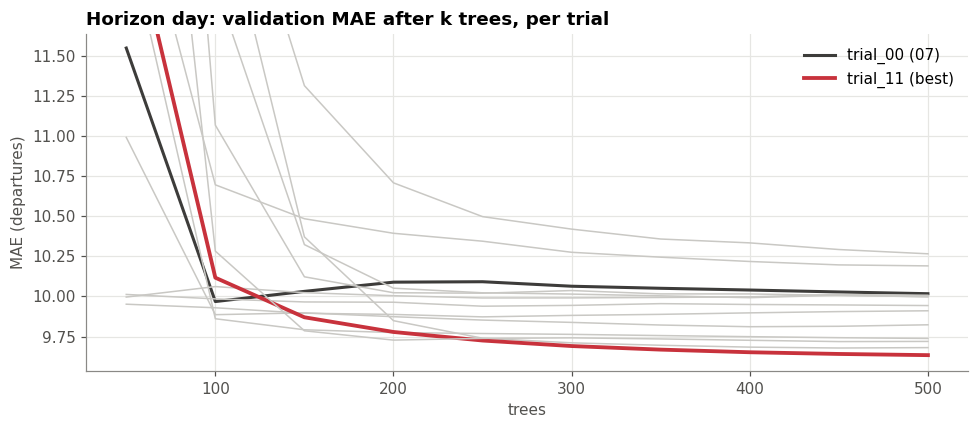

best trial trial_11: {'objective': 'regression_l1', 'learning-rate': 0.049, 'num-leaves': 255, 'min-child-samples': 1000, 'subsample': 0.84, 'colsample-bytree': 0.57}, MAE 9,634 at 500 trees; 07's configuration under the same protocol: 9,968 at 100 trees


In [4]:
best_day = trials_day.index[0]
fig, ax = plt.subplots(figsize=(9, 4))
lowest = trials_day["MAE at best"].min()
for name, result in results_day.items():
    curve = pd.Series({int(k): v for k, v in result["curve"].items()})
    style = {"color": "#c8323c", "linewidth": 2.5, "label": f"{name} (best)"} if name == best_day else \
            {"color": "#3d3c3a", "linewidth": 2, "label": "trial_00 (07)"} if name == "trial_00" else {"color": "#c9c8c4", "linewidth": 1}
    ax.plot(curve.index, curve.to_numpy(), **style)
ax.set_ylim(lowest - 0.1, lowest + 2)
ax.set_title("Horizon day: validation MAE after k trees, per trial")
ax.set_xlabel("trees")
ax.set_ylabel("MAE (departures)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"best trial {best_day}: {plain(dict(trials_day.loc[best_day, list(BASE_07['day'])]))}, "
      f"MAE {fmt(trials_day.loc[best_day, 'MAE at best'], '.3f')} at {trials_day.loc[best_day, 'best trees']} trees; "
      f"07's configuration under the same protocol: {fmt(trials_day.loc['trial_00', 'MAE at best'], '.3f')} at {trials_day.loc['trial_00', 'best trees']} trees")

### 2.3 The refit and the validation table

The best trial is fitted again with exactly its best number of trees (the same seed, so the same trees as the
first *k* of the trial) into `08_day_lightgbm`, with the model file this time. Then the rules of 05, the ridge
floor, 07's model and this one on all scorable validation rows with `score_table()`. If 07's configuration won,
the refit is 07's model with fewer trees, and the reading says the search did not move it.

In [5]:
params_day = plain({**{k: trials_day.loc[best_day, k] for k in BASE_07["day"]},
                    "n-estimators": TREES_FINAL["day"] or trials_day.loc[best_day, "best trees"]})
result_08_day = trial("day", "refit", params_day, folder=RUNS_08["day"], keep_model=True)

df = load_features()
valid_day = df[(df.split == "valid") & scorable(df, "day")]
ridge_day = ridge_predictions("day", valid_day)
candidates_day = {**rule_predictions(valid_day, "day"), **({"ridge (05)": ridge_day} if ridge_day is not None else {}),
                  "lightgbm (07)": run_predictions(RUNS_07["day"], valid_day),
                  "lightgbm (08, tuned)": run_predictions(RUNS_08["day"], valid_day)}
table_day = score_table(valid_day, candidates_day, "y_day")
assert abs(table_day.loc["lightgbm (08, tuned)", "MAE"] - result_08_day["validation"]["MAE"]) < 1e-6, "the script scored other rows"
print(f"Validation 2025, horizon day, {fmt(len(valid_day))} station-days; 08 = {params_day}")
table_day.round(2)

refit: validation MAE 9.634, best 9.634 at 500 trees (177 s)
3.872.821 rows from data\citibike\station_day_features.parquet
Validation 2025, horizon day, 779.151 station-days; 08 = {'objective': 'regression_l1', 'learning-rate': 0.049, 'num-leaves': 255, 'min-child-samples': 1000, 'subsample': 0.84, 'colsample-bytree': 0.57, 'n-estimators': 500}


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
naive (yesterday),"14,87","29,54","25,38","0,04",779.151
seasonal naive (same weekday last week),"16,08","32,34","27,46","0,16",779.151
"mean of the same weekday, 4 weeks","14,57","29,14","24,87","0,17",779.151
ridge (05),"11,92","22,67","20,34","-0,34",779.151
lightgbm (07),"10,02","19,12","17,10","1,38",779.151
"lightgbm (08, tuned)","9,63","19,00","16,45","-1,07",779.151


## 3. Horizon rest of month

### 3.1 The grid

Six configurations with 100 trees each: three leaf floors times two shares of inputs per split. The table pivots
the validation MAE and the fit time over the two axes; 07's point is (100, 1,0). The scores are on the real
total (rate x days left), as everywhere since 05. A few minutes per configuration on all rows (appendix).

In [7]:
configs_rest = {f"leaf{p['min-samples-leaf']:03d}_features{p['max-features']:.1f}": p for p in GRID_REST}
common_rest = {"n-estimators": TREES_SEARCH["rest_of_month"]}

t0 = time.time()
results_rest = {name: trial("rest_of_month", name, {**params, **common_rest}) for name, params in configs_rest.items()}
print(f"{len(results_rest)} configurations in {fmt((time.time() - t0) / 60, '.1f')} min")
trials_rest = (pd.DataFrame([trial_row(name, params, results_rest[name]) for name, params in configs_rest.items()])
               .set_index("trial").sort_values("MAE"))
display(trials_rest.round(3))
print("Validation MAE (left) and fit time in seconds (right) over the grid, 100 trees")
display(pd.concat({"MAE": trials_rest.pivot(index="min-samples-leaf", columns="max-features", values="MAE").round(2),
                   "fit (s)": trials_rest.pivot(index="min-samples-leaf", columns="max-features", values="fit (s)").round(0)}, axis=1))

leaf050_features0.5: validation MAE 110.476 (read back)
leaf050_features1.0: validation MAE 108.489 (read back)
leaf100_features0.5: validation MAE 111.942 (read back)
leaf100_features1.0: validation MAE 109.929 (read back)
leaf200_features0.5: validation MAE 114.344 (read back)
leaf200_features1.0: validation MAE 111.421 (220 s)
6 configurations in 3,7 min


,min-samples-leaf,max-features,best trees,MAE at best,MAE,WAPE_%,bias,train MAE,fit (s)
trial,,,,,,,,,
leaf050_features1.0,50,"1,0",100,"108,489","108,489","11,845","-6,082","81,472","195,1"
leaf100_features1.0,100,"1,0",100,"109,929","109,929","12,002","-7,773","87,620","197,9"
leaf050_features0.5,50,"0,5",100,"110,476","110,476","12,062","-11,908","87,509","118,1"
leaf200_features1.0,200,"1,0",100,"111,421","111,421","12,165","-9,075","93,047","206,1"
leaf100_features0.5,100,"0,5",100,"111,942","111,942","12,222","-12,568","93,248","117,4"
leaf200_features0.5,200,"0,5",100,"114,344","114,344","12,484","-12,814","98,988","103,4"


Validation MAE (left) and fit time in seconds (right) over the grid, 100 trees


MAE         fit (s)       
max-features         0.5     1.0     0.5    1.0
min-samples-leaf                               
50                110.48  108.49   118.0  195.0
100               111.94  109.93   117.0  198.0
200               114.34  111.42   103.0  206.0

### 3.2 The refit and the validation table

The best point of the grid, fitted again with 200 trees (07's number) into `08_rest_of_month_extra_trees`, with
the model file. Then the rules, the ridge floor, 07 and 08 on all scorable validation rows, and 07 against 08 per
days left in the month, where 07's bias flipped sign between the short and the long horizons.

In [8]:
best_rest = trials_rest.index[0]
params_rest = {"min-samples-leaf": int(trials_rest.loc[best_rest, "min-samples-leaf"]),
               "max-features": float(trials_rest.loc[best_rest, "max-features"]), "n-estimators": TREES_FINAL["rest_of_month"]}
result_08_rest = trial("rest_of_month", "refit", params_rest, folder=RUNS_08["rest_of_month"], keep_model=True)

valid_rest = df[(df.split == "valid") & scorable(df, "rest_of_month")]
ridge_rest = ridge_predictions("rest_of_month", valid_rest)
candidates_rest = {**rule_predictions(valid_rest, "rest_of_month"), **({"ridge (05)": ridge_rest} if ridge_rest is not None else {}),
                   "extra trees (07)": run_predictions(RUNS_07["rest_of_month"], valid_rest),
                   "extra trees (08, tuned)": run_predictions(RUNS_08["rest_of_month"], valid_rest)}
table_rest = score_table(valid_rest, candidates_rest, "y_rest_of_month")
assert abs(table_rest.loc["extra trees (08, tuned)", "MAE"] - result_08_rest["validation"]["MAE"]) < 1e-6, "the script scored other rows"
print(f"Validation 2025, horizon rest of month, {fmt(len(valid_rest))} station-days; 08 = {params_rest}")
display(table_rest.round(2))

by_length = valid_rest.assign(**{"days left": pd.cut(valid_rest.days_in_horizon, [0, 7, 14, 21, 31],
                                                      labels=["1 - 7", "8 - 14", "15 - 21", "22 - 31"])})
print("07 against 08 per days left in the month")
score_table(by_length, {k: candidates_rest[k] for k in ("extra trees (07)", "extra trees (08, tuned)")}, "y_rest_of_month", by="days left").round(2)

refit: validation MAE 108.471 (471 s)
Validation 2025, horizon rest of month, 778.126 station-days; 08 = {'min-samples-leaf': 50, 'max-features': 1.0, 'n-estimators': 200}


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
"pace, month to date x days left","169,92","398,23","18,55","21,25",778.126
"pace, last 7 days x days left","149,06","343,09","16,28","13,40",778.126
"last year, same period x growth","147,61","1.504,86","16,12","36,48",778.126
ridge (05),"150,20","314,26","16,40","1,25",778.126
extra trees (07),"109,90","254,56","12,00","-7,93",778.126
"extra trees (08, tuned)","108,47","249,77","11,84","-5,88",778.126


07 against 08 per days left in the month


,,MAE,RMSE,WAPE_%,bias,n
days left,method,,,,,
1 - 7,extra trees (07),"38,69","79,90","16,65","-9,80",179.452
8 - 14,extra trees (07),"81,19","167,06","12,78","-23,58",179.233
15 - 21,extra trees (07),"116,27","252,23","11,13","-21,75",178.979
22 - 31,extra trees (07),"179,69","369,84","11,67","15,41",240.462
1 - 7,"extra trees (08, tuned)","38,79","79,99","16,69","-9,46",179.452
8 - 14,"extra trees (08, tuned)","80,75","165,11","12,71","-22,45",179.233
15 - 21,"extra trees (08, tuned)","114,54","246,89","10,96","-18,90",178.979
22 - 31,"extra trees (08, tuned)","176,62","362,51","11,47","18,86",240.462


## 4. Reading and what carries forward

Run of 8 October 2026 (team lead), kernel DataSpell, in parts: the grid cell was run twice, so five of its six
points were read back the second time and its printed "3,7 min" is the time of the sixth point only (the fit times
in the tables are the real ones). Every assertion passed; the day refit reproduced trial 11 to the sixth decimal
(9,634349). Validation 2025, MAE in departures per station-day:

| Horizon | 07 (validation MAE) | 08, tuned | Change | What moved it |
| --- | --- | --- | --- | --- |
| day | LightGBM **10,02** (WAPE 17,1 %, bias +1,4), 1.000 trees; 9,97 at its best 100 trees | **9,63** (16,4 %, bias -1,1), 500 trees | -0,38 (-3,8 %) | 255 leaves instead of 63, the absolute error as objective, a leaf floor of 1.000 |
| rest of month | extra trees **109,9** (12,0 %, bias -7,9), 200 trees | **108,5** (11,8 %, bias -5,9), 200 trees | -1,4 (-1,3 %) | a leaf of 50 instead of 100; every input at every split, as before |

- **Day: the depth of the trees is the axis.** Every trial with 255 leaves (four) beats every trial with 127 (four),
  and those beat the two with 15; the three with 63 sit where the worst 127s are. At 255 leaves the three objectives
  are within 0,1 of each other (absolute error 9,63, Poisson 9,68, squared error 9,72): the objective is a smaller
  lever than 07 expected. What it does change is the bias, +1,4 under the squared error (the mean of a skewed count)
  and -1,1 under the absolute error (its median), while the RMSE hardly moves (19,12 -> 19,00). The train MAE is
  where 07's was (7,85 against 7,96) for a better validation: a deeper tree with a high leaf floor fits as much and
  generalises better.
- **The winner sits on the edge of the space, on three axes:** 255 leaves (the largest value offered), a leaf floor
  of 1.000 (the largest), 500 trees (the budget; its curve still falls by 0,007 per 50 trees, where 07's
  configuration was done after 100). The search found the direction, not the optimum.
- **Rest of month: a smaller leaf wins, and half the inputs loses.** With every input, 200 -> 100 -> 50 rows per
  leaf gives 111,4 -> 109,9 -> 108,5; with half the inputs every point is 2 - 3 worse and the negative bias doubles
  (-12 against -6 to -9). 50 is the smallest leaf of the grid: the edge again. 200 trees instead of 100 add 0,02.
  The gain sits in the long horizons (15 - 21 days 116,3 -> 114,5, 22 - 31 days 179,7 -> 176,6); at 1 - 7 days 08
  is a hair worse (38,7 -> 38,8). The price: 444 s to fit and a model of 1,0 GB (07: 499 MB).
- **Decision (8 October, team lead): the search stops here.** The options were a targeted probe beyond the edges in
  this notebook (a few trials, about half an hour) or a second random search; neither was taken, because the gain
  left is expected in tenths, 10 searches a widened space on SageMaker with more trials than a laptop affords, and
  09 gets one look at the test period, after which nothing is tuned. 08 is the tuned candidate, not the final
  model: 09 decides.
- **Runtime:** the 13 day trials 26,4 min (75 - 199 s each, the 255-leaf ones 2 - 3 min), the grid 15,6 min of
  fitting (103 - 206 s per point) plus the predictions, the refits 177 and 471 s: about an hour in all, against
  the 35 - 45 minutes the appendix expected.

**What 09 and 10 take from here:** the two refitted winners (`08_day_lightgbm`, `08_rest_of_month_extra_trees`)
for 09's one look at the test period, next to 05 and 07; for 10, the spaces of part 1 **widened where the winner
sat on the edge**: `num-leaves` up to 511 and 1.023, `min-child-samples` up to 2.000 and 5.000, 1.000 trees with
the curve; for the extra trees a leaf of 25 (expect about 2 GB) and `max-features` between 0,7 and 1,0; and the
trial tables as the benchmark the SageMaker job must beat (9,63 and 108,5 on the same validation rows, read from
the same `validation:MAE` line).

## Appendix: the dry run of 8 October, the expected runtime, the failures to expect

**Dry run** (Claude, 8 October, this kernel's environment, before the run on all rows). Every cell was executed by `nbclient` in the kernel's environment (Python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0) on **75 of the 2.455 stations** (the sample of 07's dry run, with its model inputs and its 07 run folders in a temporary folder): 184 s, no error, every assertion passed, the chart drawn. The 13 LightGBM trials took 2 - 26 s each on 75.597 rows, the six grid points 1 - 2 s, the two refits 4 s; the refit of the best day trial reproduced the MAE of its curve at its best number of trees to the third decimal (the same seed gives the same first *k* trees). A second execution read all 21 trials back in 8 s without training. **The numbers of that run mean nothing for the reading.**

**Expected runtime on all rows**: an extrapolation from 07's measured run, not a measurement. A LightGBM trial of 500 trees with ten curve points should take about a minute (07: 48 s to fit 1.000 trees, 127 s with the predictions), the deep ones (255 leaves, a leaf of 20) two to three, so the 13 trials about 15 - 20 minutes; an extra trees point with 100 trees about 3 minutes at `max-features` 1,0 (07: 363 s for 200 trees) and less at 0,5, so the grid about 15 minutes; the refits about 1 and 6 minutes. Expect **35 - 45 minutes** for the whole notebook; the trials are resumable, so it can be run in parts. **Measured in the run of 8 October:** the 13 day trials 75 - 199 s each (fit 40 - 87 s of it; the curve and the predictions on 779.000 rows are the rest), 26,4 min together; the grid points 103 - 206 s to fit, the ones with half the inputs the fast ones; the refits 177 s (LightGBM, fit 99 s) and 471 s (extra trees, fit 444 s); the model folders hold 12 MB (LightGBM, 500 trees of 255 leaves) and 1,0 GB (extra trees, leaf 50). About an hour in all; the notebook was run in parts, the grid cell twice.

| Symptom | Cause | Fix |
| --- | --- | --- |
| an assertion in part 0 | 07 has not been run on this machine: no model inputs or no 07 run folder | run 07 top to bottom first |
| a trial raises | the script failed inside `train.main()`; its `log.txt` in the trial folder has the output up to there | fix the cause and run the cell again: the finished trials are read back, only the failed one reruns |
| a trial is "read back" although its settings changed | the folder of that trial name still holds the old `metrics.json` | delete the folder `08_search/<horizon>/<trial>` and run the cell again |
| the search is slow | every trial is a full fit on 2,5 M rows | lower `N_RANDOM` or `TREES_SEARCH`; or let it run: the trials are resumable |
| `MemoryError` in an extra trees trial | leaf 50 with all inputs is the largest model of the grid | drop that point from `GRID_REST`, or run it alone after restarting the kernel |
| the 08 model is worse than 07 on the validation table | the refit's trees differ slightly from the trial's first *k* (thread scheduling), or the grid's best was 07's point | expected to be within hundredths; the reading records it, 09 decides on the test period |